# UBMager: Hybrid Credit Default Risk Model

**Expert System + Fuzzy Logic + Machine Learning for predicting loan default risk**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/athaaaya/Datathon_UBMager/blob/main/notebooks/ubmager_credit_risk.ipynb)

**Author:** Athaya Akbar · **Context:** Datathon competition

---

### Problem
Lenders must decide whether an applicant is likely to default *before* approving a loan. Highly accurate black-box models are hard to justify to credit analysts, while purely rule-based systems are transparent but rigid.

### Approach
This notebook builds a **hybrid model** that combines both worlds:

1. **Expert system (Certainty Factor):** encodes credit-analyst rules as confidence scores.
2. **Fuzzy C-Means clustering:** soft segmentation of applicants by age, income and employment length.
3. **Machine learning ensemble:** XGBoost, Random Forest and Logistic Regression combined with soft voting.
4. **Explainability:** SHAP values show which factors drive the predictions.

### Contents
1. Setup
2. Load and explore the data
3. Encoding and feature engineering
4. Expert system (Certainty Factor)
5. Fuzzy C-Means clustering
6. Feature set, scaling and class balancing
7. Model training and evaluation
8. Model explainability (SHAP)
9. Key insights
10. Save the model
11. Conclusion and next steps

## 1. Setup

Install the dependencies (needed in Google Colab). **Restart the runtime after installing**, then run the notebook from the next cell. Make sure `credit_risk_dataset.csv` is uploaded to the session.

In [ ]:
%pip install pandas numpy scikit-learn imbalanced-learn xgboost shap matplotlib joblib --quiet
%pip install git+https://github.com/omadson/fuzzy-c-means.git --quiet

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')  # silence library warnings before the imports below

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from fcmeans import FCM
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 2. Load and Explore the Data

The dataset contains applicant demographics, loan details and credit history. The target column `loan_status` is **1 = default** and **0 = no default**.

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")

print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head()

Rows: 32,581  |  Columns: 12


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
# Missing values and class balance
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0], end="\n\n")

print("Target distribution (loan_status):")
print(df['loan_status'].value_counts(normalize=True).rename({0: 'No default', 1: 'Default'}).round(3))

Missing values per column:
person_emp_length     895
loan_int_rate        3116
dtype: int64

Target distribution (loan_status):
loan_status
No default    0.782
Default       0.218
Name: proportion, dtype: float64


## 3. Encoding and Feature Engineering

**Encoding**
- `cb_person_default_on_file`: prior default on record, mapped from `Y`/`N` to `1`/`0`.
- `person_home_ownership`: `1` if the applicant owns their home, otherwise `0`.

**Engineered features**
- `has_fixed_asset`: home ownership as a fixed-asset indicator.
- `stable_job`: `1` if employment length is at least 5 years.
- `loan_to_income_ratio`: a clearer name for `loan_percent_income`.

**Missing values:** rows with missing values are dropped, because SMOTE and the models require complete data.

In [4]:
# Encoding
df['cb_person_default_on_file'] = df['cb_person_default_on_file'].map({'Y': 1, 'N': 0})
df['person_home_ownership'] = df['person_home_ownership'].map(lambda x: 1 if x == 'OWN' else 0)

# Feature engineering
df['has_fixed_asset'] = df['person_home_ownership']
df['stable_job'] = df['person_emp_length'].apply(lambda x: 1 if x >= 5 else 0)
df['loan_to_income_ratio'] = df['loan_percent_income']

# Drop missing values (required by SMOTE)
df = df.dropna()
print(f"Rows after cleaning: {len(df):,}")

Rows after cleaning: 28,638


## 4. Expert System (Certainty Factor)

The expert system imitates how a credit analyst reasons. Each rule that fires adds evidence, and multiple rules are combined with the Certainty Factor formula:

$$CF_{combined} = CF_1 + CF_2 \times (1 - CF_1)$$

| Evidence for **default** | CF | Evidence for **non-default** | CF |
|---|---|---|---|
| Low income and less than 1 year of employment | 0.85 | 5+ years employed and no prior default | 0.80 |
| Prior default and no fixed asset | 0.90 | High income and low loan-to-income ratio | 0.70 |
| Under 25 and low income | 0.60 | Owns a home and no prior default | 0.75 |

Output features:
- `CF_default` / `CF_nondefault`: combined confidence for each outcome.
- `CF_diff`: difference between the two.
- `expert_result`: the expert system's verdict (`1` = default if `CF_default` ≥ 0.6).

In [5]:
def rule_cf(row):
    cf_def, cf_non = [], []
    # Evidence for default
    if row['person_income'] < 4000 and row['person_emp_length'] < 1: cf_def.append(0.85)
    if row['cb_person_default_on_file'] == 1 and row['has_fixed_asset'] == 0: cf_def.append(0.9)
    if row['person_age'] < 25 and row['person_income'] < 3000: cf_def.append(0.6)

    # Evidence for non-default
    if row['person_emp_length'] >= 5 and row['cb_person_default_on_file'] == 0: cf_non.append(0.8)
    if row['person_income'] > 8000 and row['loan_percent_income'] < 0.3: cf_non.append(0.7)
    if row['has_fixed_asset'] == 1 and row['cb_person_default_on_file'] == 0: cf_non.append(0.75)

    def combine(lst):
        if not lst: return 0.0
        cf = lst[0]
        for val in lst[1:]:
            cf += val * (1 - cf)
        return round(cf, 4)

    return combine(cf_def), combine(cf_non)


df[['CF_default', 'CF_nondefault']] = df.apply(rule_cf, axis=1, result_type='expand')
df['CF_diff'] = df['CF_default'] - df['CF_nondefault']
df['expert_result'] = df['CF_default'].apply(lambda x: 1 if x >= 0.6 else 0)

df[['CF_default', 'CF_nondefault', 'CF_diff', 'expert_result']].describe().round(3)

,CF_default,CF_nondefault,CF_diff,expert_result
count,28638.000,28638.000,28638.000,28638.000
mean,0.148,0.738,-0.590,0.165
std,0.334,0.244,0.460,0.371
min,0.000,0.000,-0.985,0.000
25%,0.000,0.700,-0.940,0.000
50%,0.000,0.700,-0.700,0.000
75%,0.000,0.940,-0.700,0.000
max,0.900,0.985,0.900,1.000


## 5. Fuzzy C-Means Clustering

Fuzzy C-Means (FCM) groups applicants into **2 soft clusters** using age, income and employment length. Unlike hard clustering, each applicant has a degree of membership in every cluster (for example 60% in one, 40% in the other). The most likely cluster is used as the `fuzzy_cluster` feature.

In [6]:
fcm_features = ['person_age', 'person_income', 'person_emp_length']

fcm = FCM(n_clusters=2, random_state=RANDOM_STATE)
fcm.fit(df[fcm_features].values)
df['fuzzy_cluster'] = fcm.predict(df[fcm_features].values)

df.groupby('fuzzy_cluster')[fcm_features + ['loan_status']].mean().round(2)

,person_age,person_income,person_emp_length,loan_status
fuzzy_cluster,,,,
0,27.43,50410.82,4.51,0.25
1,29.01,135396.12,5.96,0.09


## 6. Feature Set, Scaling and Class Balancing

- **Features (`X`)**: original, engineered, expert-system and fuzzy features.
- **Target (`y`)**: `loan_status`.
- **Scaling**: Min-Max scaling to the range [0, 1].
- **Class balancing**: SMOTE creates synthetic examples of the minority (default) class.
- **Split**: 70% training, 30% testing.

In [7]:
features = [
    'person_age', 'person_income', 'person_emp_length',
    'loan_to_income_ratio', 'stable_job', 'has_fixed_asset',
    'cb_person_default_on_file', 'CF_default', 'CF_nondefault', 'CF_diff',
    'expert_result', 'fuzzy_cluster'
]
X = df[features]
y = df['loan_status']

# Scaling + SMOTE
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_scaled, y)

# Train / test split (70 / 30)
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.3, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]:,} rows  |  Test: {X_test.shape[0]:,} rows")

Train: 31,409 rows  |  Test: 13,461 rows


## 7. Model Training and Evaluation

| Model | Description |
|---|---|
| **XGBoost** | Gradient-boosted decision trees |
| **Random Forest** | Bagged ensemble of decision trees |
| **Logistic Regression** | Linear baseline |
| **Soft Voting Ensemble** | Averages the predicted probabilities of the three models |

Metrics: **precision** (how many predicted defaults are real), **recall** (how many real defaults are caught), **F1-score** (balance of the two), **accuracy** and **ROC-AUC** (ranking quality across all thresholds).

In [8]:
xgb = XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE)
rf = RandomForestClassifier(random_state=RANDOM_STATE)
logreg = LogisticRegression(max_iter=1000)
voting = VotingClassifier(estimators=[('xgb', xgb), ('rf', rf), ('logreg', logreg)], voting='soft')

models = {'XGBoost': xgb, 'Random Forest': rf, 'Logistic Regression': logreg, 'Voting Ensemble': voting}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    print(f"\n[{name}]")
    print(classification_report(y_test, y_pred))

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    })


[XGBoost]
              precision    recall  f1-score   support

           0       0.86      0.93      0.89      6759
           1       0.93      0.85      0.88      6702

    accuracy                           0.89     13461
   macro avg       0.89      0.89      0.89     13461
weighted avg       0.89      0.89      0.89     13461




[Random Forest]
              precision    recall  f1-score   support

           0       0.86      0.89      0.88      6759
           1       0.89      0.86      0.87      6702

    accuracy                           0.88     13461
   macro avg       0.88      0.88      0.88     13461
weighted avg       0.88      0.88      0.88     13461




[Logistic Regression]
              precision    recall  f1-score   support

           0       0.70      0.78      0.74      6759
           1       0.75      0.67      0.71      6702

    accuracy                           0.72     13461
   macro avg       0.73      0.72      0.72     13461
weighted avg       0.73      0.72      0.72     13461




[Voting Ensemble]
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      6759
           1       0.91      0.86      0.88      6702

    accuracy                           0.89     13461
   macro avg       0.89      0.89      0.89     13461
weighted avg       0.89      0.89      0.89     13461



In [9]:
# Model comparison
results_df = pd.DataFrame(results).set_index('Model').round(4).sort_values('ROC-AUC', ascending=False)
results_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
XGBoost,0.8892,0.9252,0.8459,0.8838,0.9554
Voting Ensemble,0.8880,0.9074,0.8630,0.8847,0.9480
Random Forest,0.8751,0.8875,0.8580,0.8725,0.9423
Logistic Regression,0.7239,0.7508,0.6668,0.7063,0.7869


## 8. Model Explainability (SHAP)

SHAP (SHapley Additive exPlanations) measures how much each feature contributes to the XGBoost model's predictions. The bar chart ranks features by their average impact.

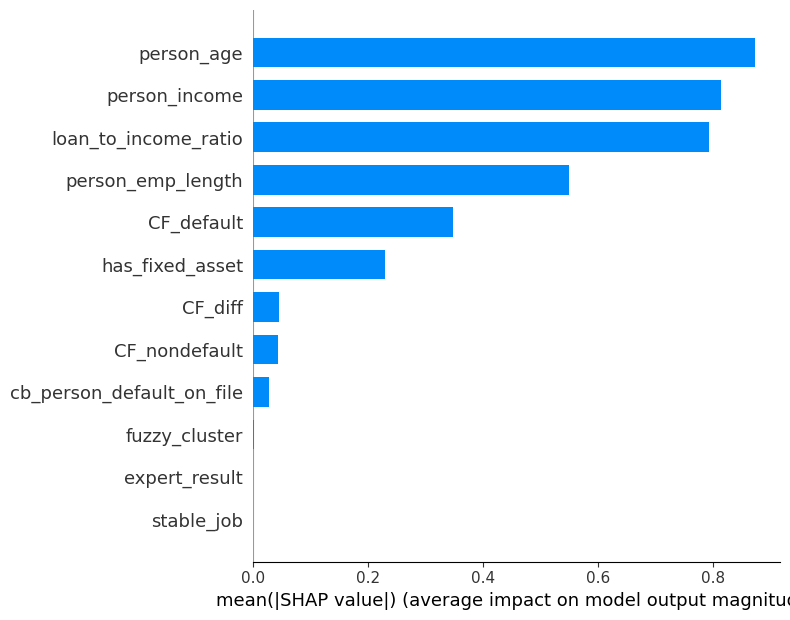

In [10]:
explainer = shap.Explainer(xgb, X_train, feature_names=X.columns)
shap_values = explainer(X_test[:50])
shap.summary_plot(shap_values, X_test[:50], plot_type="bar")

## 9. Key Insights

| Higher default risk | Lower default risk |
|---|---|
| Low income | High income |
| Age under 25 | Age over 30 |
| Less than 1 year at current job | 5+ years at current job |
| No home ownership | Owns a home (fixed asset) |
| Prior default on file | Clean credit history |
| High loan-to-income ratio (> 60%) | Low loan-to-income ratio (< 30%) |
| Expert system flags default | Supported by expert system and fuzzy clustering |

## 10. Save the Model

The final soft-voting ensemble is saved with `joblib` so it can be reused for scoring new applicants.

In [11]:
joblib.dump(voting, "ubmager_model.pkl", compress=3)
print("Model saved as ubmager_model.pkl")

Model saved as ubmager_model.pkl


## 11. Conclusion and Next Steps

**Conclusion.** Combining analyst-style rules (Certainty Factor) and fuzzy segmentation with an ML ensemble produces a credit risk model that is both predictive and explainable. The engineered expert and fuzzy features give the models domain knowledge, and SHAP makes the drivers of each prediction transparent.

**Next steps**
- Apply SMOTE **only to the training split** (after `train_test_split`) so test metrics reflect real-world class balance.
- Tune hyperparameters with cross-validated search.
- Calibrate the Certainty Factor rule thresholds against the data distribution.
- Serve the saved model through a simple API or Streamlit demo.